In [1]:
import os, sys
sys.path.append('/home/hnayak/.conda/envs/NugraphBase/lib/python3.10/site-packages')

In [2]:
import h5py
file = h5py.File("/scratch/7DayLifetime/cerati/concat-final-makeup.tiny.gnn.h5", 'r')
print(list(file.keys()))

['dataset', 'datasize', 'norm', 'planes', 'samples', 'semantic_classes']


In [3]:
(file['dataset'].keys())

<KeysViewHDF5 ['r4952_sr101_evt5074', 'r4952_sr89_evt4461', 'r4953_sr34_evt1720', 'r4954_sr23_evt1168', 'r4955_sr107_evt5396', 'r4955_sr117_evt5878', 'r4955_sr19_evt991', 'r4955_sr2_evt147', 'r4955_sr54_evt2718', 'r4955_sr67_evt3370', 'r4955_sr74_evt3740', 'r4955_sr8_evt423', 'r4957_sr130_evt6537', 'r4957_sr138_evt6925', 'r4957_sr16_evt819', 'r4957_sr40_evt2017', 'r4957_sr66_evt3323', 'r4957_sr79_evt3991', 'r4958_sr17_evt853', 'r4962_sr144_evt7222', 'r4962_sr44_evt2220', 'r4962_sr67_evt3384', 'r4966_sr4_evt215', 'r4967_sr41_evt2077', 'r4968_sr5_evt290', 'r4969_sr121_evt6069', 'r4969_sr133_evt6660', 'r4969_sr15_evt786', 'r4969_sr48_evt2406', 'r4971_sr103_evt5155', 'r4971_sr123_evt6162', 'r4971_sr137_evt6886', 'r4971_sr172_evt8601', 'r4971_sr40_evt2012', 'r4971_sr56_evt2822', 'r4971_sr65_evt3270', 'r4971_sr77_evt3863', 'r4975_sr101_evt5094', 'r4975_sr36_evt1809', 'r4975_sr47_evt2395', 'r4975_sr69_evt3464', 'r4975_sr81_evt4082', 'r4977_sr15_evt786', 'r4977_sr34_evt1726', 'r4978_sr15_evt76

In [4]:
print(len(file['dataset'].keys()))
print(file['dataset']['r4952_sr101_evt5074'])
raw = file['dataset']['r4952_sr101_evt5074'][()]
# print(len(raw))
# print(raw[12])

22074
<HDF5 dataset "r4952_sr101_evt5074": shape (), type "|V208544">


In [5]:
print(file['datasize/train'][()])
print(len(file['datasize/train'][()]))


[145088 484864 334960 ...  47936 138112  58336]
19868


In [6]:
print(file['norm'].keys())
print(file['norm/u'][()])
print(file['norm/v'][()])
print(file['norm/y'][()])

<KeysViewHDF5 ['u', 'v', 'y']>
[[390.93228   172.38268   147.52954     4.5516067]
 [147.66806    77.85538   207.89355     2.2124045]]
[[369.48965   172.28482   153.69658     4.4447336]
 [146.5169     80.36415   254.7822      1.8941015]]
[[547.42694   171.75386   116.679855    4.155394 ]
 [284.89795    73.81547   110.303856    1.4567157]]


In [7]:
print(file['semantic_classes'].asstr()[()])

['MIP' 'HIP' 'shower' 'michel' 'diffuse']


In [8]:
print(file['planes'][()])
print(file['samples'].keys())
print(len(file['samples/train'][()]))
print(file['samples/train'].asstr()[()])
print(len(file['samples/validation'][()]))
print(len(file['samples/test'][()]))

[b'u' b'v' b'y']
<KeysViewHDF5 ['test', 'train', 'validation']>
19868
['r7003_sr907_evt45383' 'r7010_sr1180_evt59039' 'r6596_sr66_evt3326' ...
 'r6548_sr99_evt4958' 'r5508_sr136_evt6838' 'r6446_sr53_evt2673']
1103
1103


In [9]:
## File @2
f2 = h5py.File("/scratch/7DayLifetime/cerati/concat-final-makeup.tiny.gnn.var.h5", 'r')
print(f2.keys())
print(len(f2['dataset'].keys()))
print(f2['samples/train'])
print(f2['samples/validation'])
print(f2['samples/test'])

<KeysViewHDF5 ['dataset', 'datasize', 'norm', 'planes', 'samples', 'semantic_classes']>
22074
<HDF5 dataset "train": shape (19868,), type "|O">
<HDF5 dataset "validation": shape (1103,), type "|O">
<HDF5 dataset "test": shape (1103,), type "|O">


## Data plot

In [10]:
import h5py
file = h5py.File("/scratch/7DayLifetime/cerati/concat-final-makeup.tiny.gnn.h5", 'r')
print(list(file.keys()))

['dataset', 'datasize', 'norm', 'planes', 'samples', 'semantic_classes']


In [11]:
%load_ext autoreload
%autoreload 2
project_root = os.path.abspath(os.path.join(os.getcwd(), "..")) 

# 2. Add that path to Python's system path so it can find your modules
if project_root not in sys.path:
    sys.path.insert(0, project_root)

# 3. Use an ABSOLUTE import (no dots at the start!)
from scripts.add_noise import modify_hdf5

In [12]:
len(file['dataset'].keys())

22074

In [13]:
data = file['dataset']['r4952_sr101_evt5074'][()]
# print(data.dtype.names)
for name in data.dtype.names:
    print(f"Feature: {name:25} | Shape: {str(data[name].shape):15} | Type: {data[name].dtype}")

Feature: metadata/run              | Shape: ()              | Type: int32
Feature: metadata/subrun           | Shape: ()              | Type: int32
Feature: metadata/event            | Shape: ()              | Type: int32
Feature: sp/num_nodes              | Shape: ()              | Type: int64
Feature: u/pos                     | Shape: (471, 2)        | Type: float32
Feature: u/x                       | Shape: (471, 2)        | Type: float32
Feature: u/id                      | Shape: (471,)          | Type: int64
Feature: u/y_semantic              | Shape: (471,)          | Type: int64
Feature: u/y_instance              | Shape: (471,)          | Type: int64
Feature: u/y_vtx                   | Shape: (1, 2)          | Type: float32
Feature: v/pos                     | Shape: (545, 2)        | Type: float32
Feature: v/x                       | Shape: (545, 2)        | Type: float32
Feature: v/id                      | Shape: (545,)          | Type: int64
Feature: v/y_semantic       

In [16]:
data['u/y_semantic']

array([-1, -1, -1, -1, -1,  4,  4,  4,  4,  4,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  0,  1,  1,  0,  1,  1,
        0,  1,  1,  0,  1,  1,  0,  1,  1,  0,  1,  1,  0,  0,  1,  1,  0,
        1,  1,  0,  1,  1,  0,  1,  1,  0,  0,  1,  0,  0,  0,  1,  4,  0,
        0,  1,  4,  0,  0,  1,  4,  0,  1,  1,  1])

In [17]:
# import h5py
# import numpy as np
# import matplotlib.pyplot as plt
# from matplotlib.colors import LogNorm

# # 1. Load the data
# file_path = "/scratch/7DayLifetime/cerati/concat-final-makeup.tiny.gnn.h5"
# file = h5py.File(file_path, 'r')
# dataset_group = file['dataset']

# planes = ['u', 'v', 'y']

# # Set up dictionaries to hold the aggregated arrays
# combined_time = {plane: [] for plane in planes}
# combined_rms = {plane: [] for plane in planes}

# print(f"Aggregating {len(dataset_group.keys())} events...")

# # 2. Loop through all events and collect Time and RMS
# for key in dataset_group.keys():
#     data = dataset_group[key][()]
    
#     for plane in planes:
#         # Time is the 2nd element of 'pos' (index 1)
#         combined_time[plane].append(data[f'{plane}/pos'][:, 1])
        
#         # RMS is the 2nd element of 'x' (index 1)
#         combined_rms[plane].append(data[f'{plane}/x'][:, 1])

# # 3. Concatenate the lists into massive 1D arrays
# for plane in planes:
#     combined_time[plane] = np.concatenate(combined_time[plane])
#     combined_rms[plane] = np.concatenate(combined_rms[plane])

# # 4. Create the 2D Histograms
# fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# fig.suptitle("Aggregated RMS vs. Peak Time (Entire Dataset)", fontsize=16)

# for i, plane in enumerate(planes):
#     time_data = combined_time[plane]
#     rms_data = combined_rms[plane]
    
#     # Create the 2D histogram
#     # Using LogNorm for the colors makes it much easier to see the structure 
#     # if you have a dense core and sparse outliers
#     h = axes[i].hist2d(time_data, rms_data, bins=100, cmap='viridis', norm=LogNorm())
    
#     axes[i].set_title(f'Plane {plane.upper()} (Entries: {len(time_data):,})')
#     axes[i].set_xlabel('Peak Time')
#     axes[i].set_ylabel('RMS')
    
#     # Add a colorbar to each subplot to show the density scale
#     fig.colorbar(h[3], ax=axes[i], label='Number of Nodes')

# plt.tight_layout()

# # Save as PDF
# output_pdf = "rms_vs_time_aggregated.pdf"
# plt.savefig(output_pdf, format='pdf', bbox_inches='tight')
# print(f"Plot saved to {output_pdf}")

# # Display
# plt.show()

In [ ]:
# import h5py
# import numpy as np
# import matplotlib.pyplot as plt

# # 1. Load the data
# file_path = "/scratch/7DayLifetime/cerati/concat-final-makeup.tiny.gnn.h5"
# file = h5py.File(file_path, 'r')
# dataset_group = file['dataset']

# planes = ['u', 'v', 'y']

# # Set up dictionaries to hold the aggregated arrays
# combined_time = {plane: [] for plane in planes}
# combined_rms = {plane: [] for plane in planes}

# print(f"Aggregating {len(dataset_group.keys())} events...")

# # 2. Loop through all events and collect Time and RMS
# for key in dataset_group.keys():
#     data = dataset_group[key][()]
    
#     for plane in planes:
#         valid_mask = data[f'{plane}/y_semantic'] > -1
#         filtered_time = data[f'{plane}/pos'][valid_mask, 1]
#         combined_time[plane].append(filtered_time)
#         filtered_rms = data[f'{plane}/x'][valid_mask, 1]
#         combined_rms[plane].append(filtered_rms)

# # 3. Concatenate the lists into massive 1D arrays
# for plane in planes:
#     combined_time[plane] = np.concatenate(combined_time[plane])
#     combined_rms[plane] = np.concatenate(combined_rms[plane])

# # ==========================================
# # 4. Setup the Ridge Plot Parameters
# # ==========================================
# y_min_val, y_max_val = 0, 400
# y_bins = np.linspace(y_min_val, y_max_val, num=15)
# y_step = y_bins[1] - y_bins[0]  # Distance between ridges

# x_min_val, x_max_val = 0, 10
# x_bins = np.linspace(x_min_val, x_max_val, num=60)
# x_centers = (x_bins[:-1] + x_bins[1:]) / 2

# # Create the figure with 3 subplots side-by-side
# # Increased height to 8 so the ridges have room to breathe
# fig, axes = plt.subplots(1, 3, figsize=(18, 8))
# fig.suptitle("Aggregated RMS vs. Peak Time (Per Plane)", fontsize=16)

# overlap_factor = 1.5 

# # ==========================================
# # 5. Build the Ridges for Each Plane
# # ==========================================
# for i, plane in enumerate(planes):
#     ax = axes[i]
#     time_data = combined_time[plane]
#     rms_data = combined_rms[plane]
    
#     # Loop from top to bottom to draw ridges
#     for j in reversed(range(len(y_bins) - 1)):
#         y_start = y_bins[j]
#         y_end = y_bins[j+1]
        
#         mask = (time_data >= y_start) & (time_data < y_end)
#         slice_data = rms_data[mask]
            
#         hist, _ = np.histogram(slice_data, bins=x_bins)
        
#         # Scale histogram dynamically
#         if hist.max() > 0:
#             hist_scaled = (hist / hist.max()) * (y_step * overlap_factor)
#         else:
#             hist_scaled = hist
            
#         y_offset = y_start 
        
#         # Draw the ridge
#         ax.plot([x_min_val, x_max_val], [y_offset, y_offset], color='black', linestyle='--', linewidth=0.5, zorder=len(y_bins)-j)
#         ax.fill_between(x_centers, y_offset, hist_scaled + y_offset, step='mid', color='white', zorder=len(y_bins)-j)
#         ax.step(x_centers, hist_scaled + y_offset, where='mid', color='black', linewidth=1.2, zorder=len(y_bins)-j)

#     # Styling for this specific subplot
#     ax.set_xlim(x_min_val, x_max_val)
#     ax.set_ylim(y_min_val, y_max_val)
#     ax.set_xlabel("RMS", fontsize=12)
#     ax.set_title(f'Plane {plane.upper()} (Entries: {len(time_data):,})', fontsize=14)
    
#     # Only label the Y-axis on the far-left plot to avoid clutter
#     if i == 0:
#         ax.set_ylabel("Peak Time", fontsize=12)
        
#     ax.minorticks_on()
#     ax.tick_params(which='both', direction='in', top=True, right=True)

# plt.tight_layout()

# # Save as PDF
# output_pdf = "rms_time_ridge_per_plane.pdf"
# plt.savefig(output_pdf, format='pdf', bbox_inches='tight')
# print(f"Plot saved to {output_pdf}")

# # Display
# plt.show()

In [20]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

# 1. Load the data
file_path = "/scratch/7DayLifetime/cerati/numiallwr2.half.gnn.h5"
# file_path = "/scratch/7DayLifetime/cerati/concat-final-makeup.tiny.gnn.h5"
file = h5py.File(file_path, 'r')
dataset_group = file['dataset']

# Set up lists to hold the combined arrays for ALL planes
combined_time = []
combined_rms = []
planes = ['u', 'v', 'y']

print("Aggregating data across all events and all planes...")

for key in dataset_group.keys():
    data = dataset_group[key][()]
    
    # Loop through planes and add them all to the same list
    for plane in planes:
        valid_mask = data[f'{plane}/y_semantic'] > -1
        filtered_time = data[f'{plane}/pos'][valid_mask, 1]
        combined_time.append(filtered_time)
        filtered_rms = data[f'{plane}/x'][valid_mask, 1]
        combined_rms.append(filtered_rms)
        # combined_time.append(data[f'{plane}/pos'][:, 1]) 
        # combined_rms.append(data[f'{plane}/x'][:, 1])

# Concatenate everything into single massive 1D arrays
combined_time = np.concatenate(combined_time)
combined_rms = np.concatenate(combined_rms)



Aggregating data across all events and all planes...


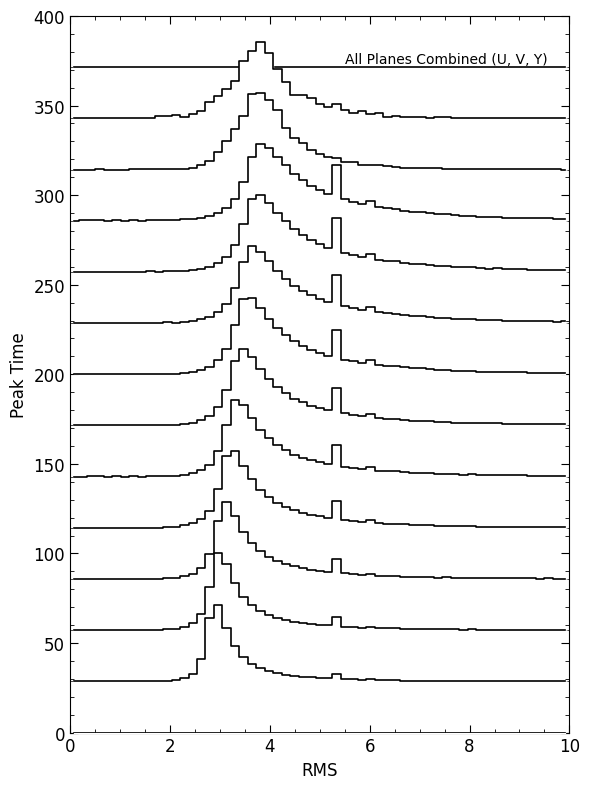

In [21]:
# ==========================================
# 2. Setup the Ridge Plot Parameters
# ==========================================
# Define the bins for the Y-axis (Drift Time slices)
y_min_val, y_max_val = 0, 400
y_bins = np.linspace(y_min_val, y_max_val, num=15) # 40 ridges
y_step = y_bins[1] - y_bins[0]  # Calculate the distance between ridges

# Define the bins for the X-axis (The RMS distribution)
x_min_val, x_max_val = 0, 10
x_bins = np.linspace(x_min_val, x_max_val, num=60)
x_centers = (x_bins[:-1] + x_bins[1:]) / 2

# Create a single figure
fig, ax = plt.subplots(figsize=(6, 8))

# ==========================================
# 3. Build the Ridges
# ==========================================
# Overlap factor: 1.5 means the tallest peak in a ridge will reach halfway into the ridge above it
overlap_factor = 1.5 

# Loop from top to bottom so lower ridges are drawn last (appearing in front)
for i in reversed(range(len(y_bins) - 1)):
    y_start = y_bins[i]
    y_end = y_bins[i+1]
    
    # Isolate the data that falls into this specific time slice
    mask = (combined_time >= y_start) & (combined_time < y_end)
    slice_data = combined_rms[mask]
        
    # Calculate the histogram for this slice
    hist, _ = np.histogram(slice_data, bins=x_bins)
    
    # Scale the histogram dynamically based on the y_step
    if hist.max() > 0:
        # Normalizes to 0-1, then scales to fit the vertical spacing
        hist_scaled = (hist / hist.max()) * (y_step * overlap_factor)
    else:
        hist_scaled = hist
        
    # The vertical baseline for this specific ridge
    y_offset = y_start 
    
    # Plot 1: The dashed baseline
    ax.plot([x_min_val, x_max_val], [y_offset, y_offset], color='black', linestyle='--', linewidth=0.5, zorder=len(y_bins)-i)
    
    # Plot 2: The solid white fill (hides lines behind it)
    ax.fill_between(x_centers, y_offset, hist_scaled + y_offset, step='mid', color='white', zorder=len(y_bins)-i)
    
    # Plot 3: The black stepped outline
    ax.step(x_centers, hist_scaled + y_offset, where='mid', color='black', linewidth=1.2, zorder=len(y_bins)-i)

# ==========================================
# 4. Styling
# ==========================================
ax.set_xlim(x_min_val, x_max_val)
ax.set_ylim(y_min_val, y_max_val)

# CORRECTED: Changed label to reflect raw RMS values
ax.set_xlabel("RMS", fontsize=12)
ax.set_ylabel("Peak Time", fontsize=12)

# Add minor ticks
ax.minorticks_on()
ax.tick_params(which='both', direction='in', top=True, right=True)
ax.tick_params(which='major', length=6, labelsize=12)
ax.tick_params(which='minor', length=3)

# Add text box indicating all planes are combined
ax.text(0.55, 0.95, "All Planes Combined (U, V, Y)", 
        transform=ax.transAxes, verticalalignment='top',horizontalalignment='left', fontsize=10)

plt.tight_layout()
plt.savefig("rms_time_combinedplanes.pdf", format='pdf')
plt.savefig("rms_time_combinedplanes.png", format='png')
plt.show()

would identify the primary peaks in the time vs RMS plane for both and find the linear function that connects them. Then we need to rescale the RMS value of the second sample (as a function of time) so that the two lines match

## Mapping dataset 1 to dataset 2

In [2]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. Helper Function to Load & Filter Data
# ==========================================
def load_and_aggregate(file_path):
    print(f"Loading {file_path}...")
    file = h5py.File(file_path, 'r')
    dataset_group = file['dataset']
    
    combined_time = []
    combined_rms = []
    planes = ['u', 'v', 'y']
    
    for key in dataset_group.keys():
        data = dataset_group[key][()]
        for plane in planes:
            # Apply your semantic mask
            valid_mask = data[f'{plane}/y_semantic'] > -1
            combined_time.append(data[f'{plane}/pos'][valid_mask, 1])
            combined_rms.append(data[f'{plane}/x'][valid_mask, 1])
            
    return np.concatenate(combined_time), np.concatenate(combined_rms)


def get_peak_coordinates(time_data, rms_data):
    peak_t = []
    peak_r = []
    
    for i in range(len(y_bins) - 1):
        t_start, t_end = y_bins[i], y_bins[i+1]
        mask = (time_data >= t_start) & (time_data < t_end)
        
        # Only process if there are enough nodes in this time slice
        if np.sum(mask) > 50: 
            slice_rms = rms_data[mask]
            hist, _ = np.histogram(slice_rms, bins=x_bins)
            
            # Find the RMS value with the highest node count
            max_bin_index = np.argmax(hist)
            peak_r.append(x_centers[max_bin_index])
            peak_t.append((t_start + t_end) / 2.0)
            
    return np.array(peak_t), np.array(peak_r)
# Load your two datasets
file_path_1 = "/scratch/7DayLifetime/cerati/numiallwr2.half.gnn.h5"
file_path_2 = "/scratch/7DayLifetime/cerati/concat-final-makeup.tiny.gnn.h5"

time_1, rms_1 = load_and_aggregate(file_path_1)
time_2, rms_2 = load_and_aggregate(file_path_2)



Loading /scratch/7DayLifetime/cerati/numiallwr2.half.gnn.h5...
Loading /scratch/7DayLifetime/cerati/concat-final-makeup.tiny.gnn.h5...


In [8]:
# # ==========================================
# # 2. Find Peaks and Fit Linear Functions
# # ==========================================
# # Define bins based on your screenshots (Time 0-400, RMS 0-10)
# y_bins = np.linspace(0, 400, 15)
# x_bins = np.linspace(0, 10, 60)
# x_centers = (x_bins[:-1] + x_bins[1:]) / 2



# print("Extracting peaks and calculating linear fits...")
# t1_peaks, r1_peaks = get_peak_coordinates(time_1, rms_1)
# t2_peaks, r2_peaks = get_peak_coordinates(time_2, rms_2)

# # Fit a 1st-degree polynomial (a line) to Time vs. Peak RMS
# m1, b1 = np.polyfit(t1_peaks, r1_peaks, 1)
# m2, b2 = np.polyfit(t2_peaks, r2_peaks, 1)

# print(f"Dataset 1 Line: RMS = {m1:.5f}*t + {b1:.5f}")
# print(f"Dataset 2 Line: RMS = {m2:.5f}*t + {b2:.5f}")

# # ==========================================
# # 3. Rescale Dataset 2
# # ==========================================
# print("Rescaling Dataset 2 to match Dataset 1...")

# # For every node in Dataset 2, calculate where its peak SHOULD be (Target) 
# # and where it CURRENTLY is, based on its specific peak time
# target_peak_at_t = (m1 * time_2) + b1
# current_peak_at_t = (m2 * time_2) + b2

# # Apply the mathematical mapping
# rms_2_rescaled = rms_2 * (target_peak_at_t / current_peak_at_t)

# # ==========================================
# # 4. Plot the Rescaled Ridge Plot
# # ==========================================
# fig, ax = plt.subplots(figsize=(6, 8))
# y_step = y_bins[1] - y_bins[0]
# overlap_factor = 1.5 

# for i in reversed(range(len(y_bins) - 1)):
#     y_start, y_end = y_bins[i], y_bins[i+1]
#     mask = (time_2 >= y_start) & (time_2 < y_end)
    
#     # IMPORTANT: We are plotting the RESCALED RMS array now
#     slice_data = rms_2_rescaled[mask] 
        
#     hist, _ = np.histogram(slice_data, bins=x_bins)
    
#     if hist.max() > 0:
#         hist_scaled = (hist / hist.max()) * (y_step * overlap_factor)
#     else:
#         hist_scaled = hist
        
#     y_offset = y_start 
#     ax.plot([0, 10], [y_offset, y_offset], color='black', linestyle='--', linewidth=0.5, zorder=len(y_bins)-i)
#     ax.fill_between(x_centers, y_offset, hist_scaled + y_offset, step='mid', color='white', zorder=len(y_bins)-i)
#     ax.step(x_centers, hist_scaled + y_offset, where='mid', color='black', linewidth=1.2, zorder=len(y_bins)-i)

# ax.set_xlim(0, 10)
# ax.set_ylim(0, 400)
# ax.set_xlabel("RMS (Rescaled)", fontsize=12)
# ax.set_ylabel("Peak Time", fontsize=12)
# ax.minorticks_on()
# ax.tick_params(which='both', direction='in', top=True, right=True)
# ax.text(0.95, 0.95, "Dataset 2 (Calibrated to Dataset 1)\nAll Planes Combined", 
#         transform=ax.transAxes, verticalalignment='top', horizontalalignment='right', fontsize=10)

# plt.tight_layout()
# plt.savefig("dataset2_rescaled_ridges.pdf", format='pdf')
# plt.show()

Extracting peaks and calculating linear fits...
Dataset 1 Line: RMS = 0.00311*t + 2.85232
Dataset 2 Line: RMS = 0.00496*t + 2.72322
Rescaling Dataset 2 to match Dataset 1...


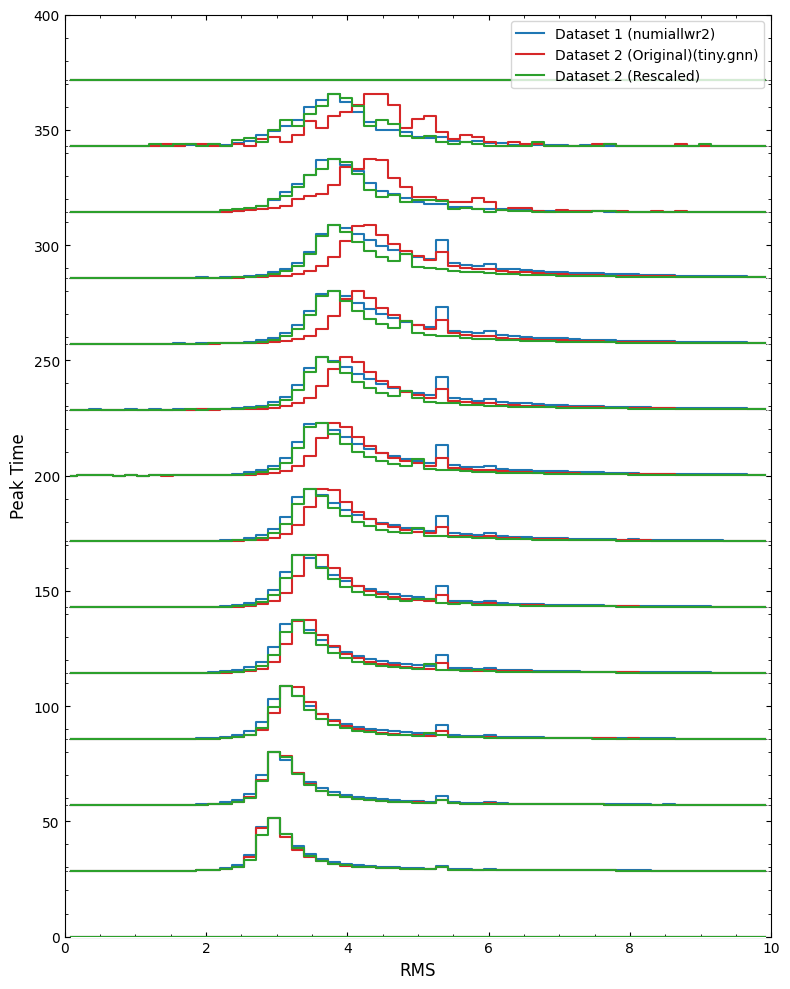

In [7]:
# ==========================================
# 2. Find Peaks and Fit Linear Functions
# ==========================================
# Define bins based on your screenshots (Time 0-400, RMS 0-10)
y_bins = np.linspace(0, 400, 15)
x_bins = np.linspace(0, 10, 60)
x_centers = (x_bins[:-1] + x_bins[1:]) / 2



print("Extracting peaks and calculating linear fits...")
t1_peaks, r1_peaks = get_peak_coordinates(time_1, rms_1)
t2_peaks, r2_peaks = get_peak_coordinates(time_2, rms_2)

# Fit a 1st-degree polynomial (a line) to Time vs. Peak RMS
m1, b1 = np.polyfit(t1_peaks, r1_peaks, 1)
m2, b2 = np.polyfit(t2_peaks, r2_peaks, 1)

print(f"Dataset 1 Line: RMS = {m1:.5f}*t + {b1:.5f}")
print(f"Dataset 2 Line: RMS = {m2:.5f}*t + {b2:.5f}")

# ==========================================
# 3. Rescale Dataset 2
# ==========================================
print("Rescaling Dataset 2 to match Dataset 1...")

# For every node in Dataset 2, calculate where its peak SHOULD be (Target) 
# and where it CURRENTLY is, based on its specific peak time
target_peak_at_t = (m1 * time_2) + b1
current_peak_at_t = (m2 * time_2) + b2

# Apply the mathematical mapping
rms_2_rescaled = rms_2 * (target_peak_at_t / current_peak_at_t)


# ==========================================
# 4. Plot the Overlapped Ridges (Outlines Only)
# ==========================================
fig, ax = plt.subplots(figsize=(8, 10)) # Made slightly wider for the 3-item legend
y_step = y_bins[1] - y_bins[0]
overlap_factor = 0.8

for i in reversed(range(len(y_bins) - 1)):
    y_start, y_end = y_bins[i], y_bins[i+1]
    y_offset = y_start 
    z_idx = len(y_bins) - i
    
    # --- Process Dataset 2 (Original) ---
    mask_2_orig = (time_2 >= y_start) & (time_2 < y_end)
    slice_data_2_orig = rms_2[mask_2_orig] 
    hist_2_orig, _ = np.histogram(slice_data_2_orig, bins=x_bins)
    
    if hist_2_orig.max() > 0:
        hist_scaled_2_orig = (hist_2_orig / hist_2_orig.max()) * (y_step * overlap_factor)
    else:
        hist_scaled_2_orig = hist_2_orig

    # --- Process Dataset 2 (Rescaled) ---
    slice_data_2_rescaled = rms_2_rescaled[mask_2_orig] # Uses the same time mask
    hist_2_rescaled, _ = np.histogram(slice_data_2_rescaled, bins=x_bins)
    
    if hist_2_rescaled.max() > 0:
        hist_scaled_2_rescaled = (hist_2_rescaled / hist_2_rescaled.max()) * (y_step * overlap_factor)
    else:
        hist_scaled_2_rescaled = hist_2_rescaled
        
    # --- Process Dataset 1 (Target) ---
    mask_1 = (time_1 >= y_start) & (time_1 < y_end)
    slice_data_1 = rms_1[mask_1]
    hist_1, _ = np.histogram(slice_data_1, bins=x_bins)
    
    if hist_1.max() > 0:
        hist_scaled_1 = (hist_1 / hist_1.max()) * (y_step * overlap_factor)
    else:
        hist_scaled_1 = hist_1

    # --- Plotting ---
    # Create a solid white background covering the highest peak of ALL THREE datasets 
    combined_max = np.maximum.reduce([hist_scaled_1, hist_scaled_2_orig, hist_scaled_2_rescaled])
    
    # 1. Dashed baseline
    ax.plot([0, 10], [y_offset, y_offset], color='black', linestyle='--', linewidth=0.5, zorder=z_idx)
    
    # 2. Solid white fill mask (Hides the older ridges drawn behind this slice)
    ax.fill_between(x_centers, y_offset, combined_max + y_offset, step='mid', color='white', zorder=z_idx)
    
    # 3. Plot Dataset 1 (Blue Outline)
    label_1 = 'Dataset 1 (numiallwr2)' if i == 0 else ""
    ax.step(x_centers, hist_scaled_1 + y_offset, where='mid', color='#1f77b4', linewidth=1.5, label=label_1, zorder=z_idx)
    
    # 4. Plot Dataset 2 Original (Red Outline)
    label_2_orig = 'Dataset 2 (Original)(tiny.gnn)' if i == 0 else ""
    ax.step(x_centers, hist_scaled_2_orig + y_offset, where='mid', color='#d62728', linewidth=1.5, label=label_2_orig, zorder=z_idx)

    # 5. Plot Dataset 2 Rescaled (Green Outline)
    label_2_rescaled = 'Dataset 2 (Rescaled)' if i == 0 else ""
    ax.step(x_centers, hist_scaled_2_rescaled + y_offset, where='mid', color='#2ca02c', linewidth=1.5, label=label_2_rescaled, zorder=z_idx)

# ==========================================
# 5. Styling & Legends
# ==========================================
ax.set_xlim(0, 10)
ax.set_ylim(0, 400)
ax.set_xlabel("RMS", fontsize=12)
ax.set_ylabel("Peak Time", fontsize=12)
ax.minorticks_on()
ax.tick_params(which='both', direction='in', top=True, right=True)

# Add Legend
ax.legend(loc='upper right', frameon=True, fontsize=10)

plt.tight_layout()
plt.savefig("dataset_overlap_outlines.pdf", format='pdf')
plt.savefig("dataset_overlap_outlines.png", format='png')

plt.show()

# Mapping dataset 1 to dataset 2 plane wise

# Plot INTEGRAL

In [13]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

def load_integral_data(file_path):
    """Helper function to load the time and integral arrays from a single file."""
    print(f"Loading {file_path}...")
    file = h5py.File(file_path, 'r')
    dataset_group = file['dataset']
    
    combined_time = []
    combined_integral = []
    planes = ['u', 'v', 'y']
    
    for key in dataset_group.keys():
        data = dataset_group[key][()]
        for plane in planes:
            valid_mask = data[f'{plane}/y_semantic'] > -1
            
            # Index 1 is Time, Index 0 is Integral
            combined_time.append(data[f'{plane}/pos'][valid_mask, 1])
            combined_integral.append(data[f'{plane}/x'][valid_mask, 0])
            
    return np.concatenate(combined_time), np.concatenate(combined_integral)

def plot_integral_ridges(datasets, labels, x_min=0, x_max=200, overlap_factor=0.8):
    """
    Draws a ridge plot using pre-loaded data. 
    'datasets' should be a list of tuples: [(time_1, int_1), (time_2, int_2), ...]
    """
    if isinstance(labels, str):
        labels = [labels]
        
    # 1. Setup Bins and Plot Parameters
    y_bins = np.linspace(0, 400, 15)
    y_step = y_bins[1] - y_bins[0]
    
    x_bins = np.linspace(x_min, x_max, 60)
    x_centers = (x_bins[:-1] + x_bins[1:]) / 2

    # A distinct color palette
    colors = ['#1f77b4', '#d62728', '#2ca02c', '#ff7f0e', '#9467bd']
    
    fig, ax = plt.subplots(figsize=(8, 10))

    # 2. Build the Ridges
    for i in reversed(range(len(y_bins) - 1)):
        y_start, y_end = y_bins[i], y_bins[i+1]
        y_offset = y_start 
        z_idx = len(y_bins) - i
        
        histograms = []
        
        # Calculate and scale the histogram for every dataset in this time slice
        for idx, (t_data, int_data) in enumerate(datasets):
            mask = (t_data >= y_start) & (t_data < y_end)
            slice_data = int_data[mask]
            
            hist, _ = np.histogram(slice_data, bins=x_bins)
            
            if hist.max() > 0:
                hist_scaled = (hist / hist.max()) * (y_step * overlap_factor)
            else:
                hist_scaled = np.zeros_like(hist, dtype=float)
                
            histograms.append(hist_scaled)
            
        # Create the solid white mask up to the tallest point of ANY dataset in this slice
        if histograms:
            combined_max = np.maximum.reduce(histograms)
        else:
            combined_max = np.zeros_like(x_centers)
            
        # Draw Baseline and White Mask
        ax.plot([x_min, x_max], [y_offset, y_offset], color='black', linestyle='--', linewidth=0.5, zorder=z_idx)
        ax.fill_between(x_centers, y_offset, combined_max + y_offset, step='mid', color='white', zorder=z_idx)
        
        # Draw the outlines for each dataset
        for idx, hist_scaled in enumerate(histograms):
            lbl = labels[idx] if i == 0 else ""
            c = colors[idx % len(colors)]
            ax.step(x_centers, hist_scaled + y_offset, where='mid', color=c, linewidth=1.5, label=lbl, zorder=z_idx)

    # 3. Styling
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(0, 400)
    ax.set_xlabel("Integral (Index 0)", fontsize=12)
    ax.set_ylabel("Peak Time", fontsize=12)
    ax.minorticks_on()
    ax.tick_params(which='both', direction='in', top=True, right=True)
    
    ax.legend(loc='upper right', frameon=True, fontsize=10)
    
    plt.tight_layout()
    plt.savefig("integral_ridges.png", format='png')
    print("Plot saved to integral_ridges.png")
    plt.show()
    


In [ ]:
# %% Load Data
file_list = [
    "/scratch/7DayLifetime/cerati/numiallwr2.half.gnn.h5", 
    "/scratch/7DayLifetime/cerati/concat-final-makeup.tiny.gnn.h5"
]

print("Starting data load...")
loaded_datasets = []
for path in file_list:
    loaded_datasets.append(load_integral_data(path))
print("Data loading complete! Ready to plot.")

Plot saved to integral_ridges.png


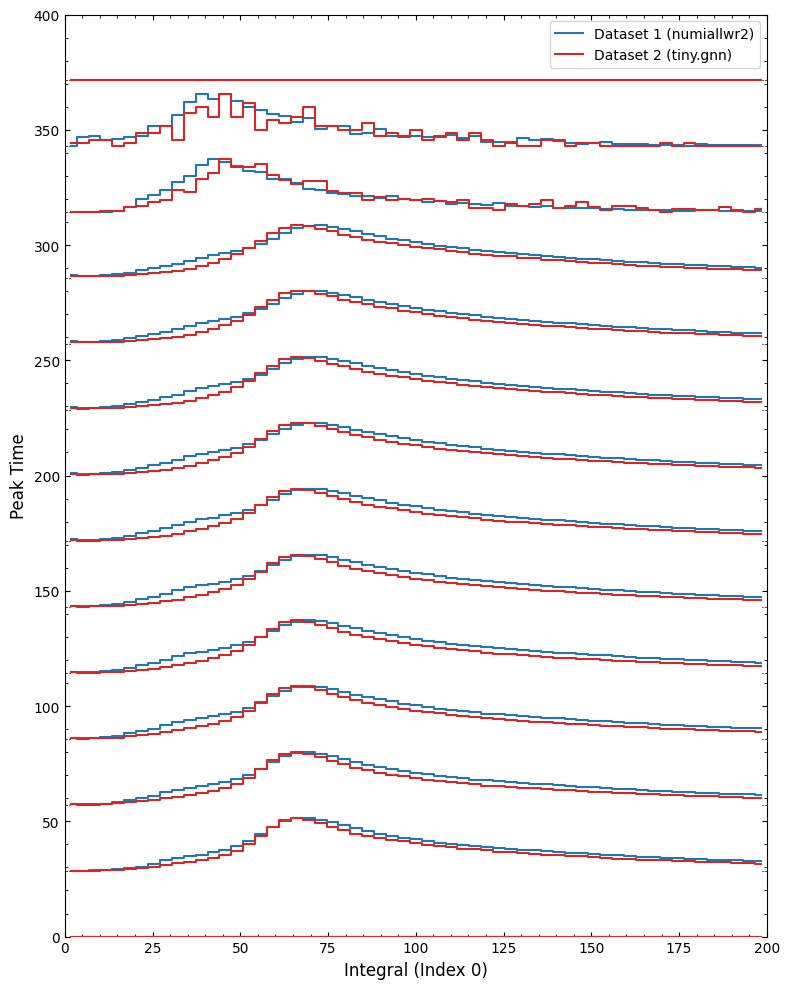

In [14]:
# %% Plot Data
label_list = [
    "Dataset 1 (numiallwr2)", 
    "Dataset 2 (tiny.gnn)"
]

# Pass the 'loaded_datasets' variable directly into the plot function
plot_integral_ridges(loaded_datasets, label_list, x_min=0, x_max=200, overlap_factor=0.8)

## END

# Mimicing the simulated data to real data based on the figure 5 (a) from this paper 
#### integral for each plane is being shifted (https://arxiv.org/pdf/2111.03556) 


In [24]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binned_statistic

def load_integral_data_per_plane(file_path):
    """Helper function to load the time and integral arrays from a single file."""
    print(f"Loading {file_path}...")
    file = h5py.File(file_path, 'r')
    dataset_group = file['dataset']

    planes = ['u', 'v', 'y']
    combined_time = {plane: [] for plane in planes}
    combined_integral = {plane: [] for plane in planes}
    
    for key in dataset_group.keys():
        data = dataset_group[key][()]
        for plane in planes:
            valid_mask = data[f'{plane}/y_semantic'] > -1
            
            # Index 1 is Time, Index 0 is Integral
            combined_time[plane].append(data[f'{plane}/pos'][valid_mask, 1])
            combined_integral[plane].append(data[f'{plane}/x'][valid_mask, 0])

    # 3. Concatenate the lists into massive 1D arrays
    for plane in planes:
        combined_time[plane] = np.concatenate(combined_time[plane])
        combined_integral[plane] = np.concatenate(combined_integral[plane])
    return combined_time, combined_integral

def plot_integral_per_plane(combined_time, combined_integral):
    # 4. Create the 2D Histograms
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle("Aggregated integral vs. Peak Time (Entire Dataset)", fontsize=16)
    planes = ['u', 'v', 'y']
    for i, plane in enumerate(planes):
        time_data = combined_time[plane]
        integral_data = combined_integral[plane]
        
        # mean_vals, bin_edges, _ = binned_statistic(time_data, integral_data, statistic='mean', bins=35)
        median_vals, bin_edges, _ = binned_statistic(time_data, integral_data, statistic='median', bins=35) 
        bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
        
        # axes[0, i].plot(bin_centers, mean_vals, marker='o', linestyle='-', color='blue')
        # axes[0, i].set_title(f'Plane {plane.upper()} - MEAN')
        # axes[0, i].set_xlabel('Peak Time')
        # axes[0, i].set_ylabel('Mean Integral')
        # axes[0, i].grid(True, linestyle='--', alpha=0.6)
        
        # 4. Plot the MEDIAN (Bottom row: axes[1, i])
        axes[i].plot(bin_centers, median_vals, marker='s', linestyle='-', color='red')
        axes[i].set_title(f'Plane {plane.upper()} - MEDIAN')
        axes[i].set_xlabel('Peak Time')
        axes[i].set_ylabel('Median Integral')
        axes[i].grid(True, linestyle='--', alpha=0.6) 
        axes[i].set_xlim(0, 300)
    plt.savefig("integral_vs_time_per_plane.pdf", bbox_inches="tight")
    plt.tight_layout()
    plt.show()


def apply_hybrid_time_corrections(time_data, raw_integrals, plane):
    """
    Applies fixed scalars for planes 'v' and 'y', and a step-wise 
    correction function for plane 'u' based on derived time bins.
    """
    if plane == 'v':
        # Plane 1 average
        return raw_integrals * 1.025
        
    elif plane == 'y':
        # Plane 2 average
        return raw_integrals * 0.97
        
    elif plane == 'u':
        # Mapped time boundaries: Peak Time = Position(cm) + 50
        t_50cm = 100   
        t_120cm = 170 
        t_175cm = 225 
        
        conditions = [
            (time_data < t_50cm),
            (time_data >= t_50cm) & (time_data < t_120cm),
            (time_data >= t_120cm) & (time_data < t_175cm),
            (time_data >= t_175cm)
        ]
        
        # Scaling factors from the MicroBooNE plot
        choices = [
            1.01,  # 0 - 50 cm
            1.025,  # 50 - 120 cm
            1.05,  # 120 - 175 cm
            1.04   # 175+ cm
        ]
        
        correction_factors = np.select(conditions, choices, default=1.0)
        
        return raw_integrals * correction_factors
        
    else:
        raise ValueError(f"Unknown plane: {plane}")

In [6]:
# file_path = "/scratch/7DayLifetime/cerati/numiallwr2.half.gnn.h5"
file_path = "/scratch/7DayLifetime/cerati/concat-final-makeup.tiny.gnn.h5"
c_time, c_int = load_integral_data_per_plane (file_path)

Loading /scratch/7DayLifetime/cerati/concat-final-makeup.tiny.gnn.h5...


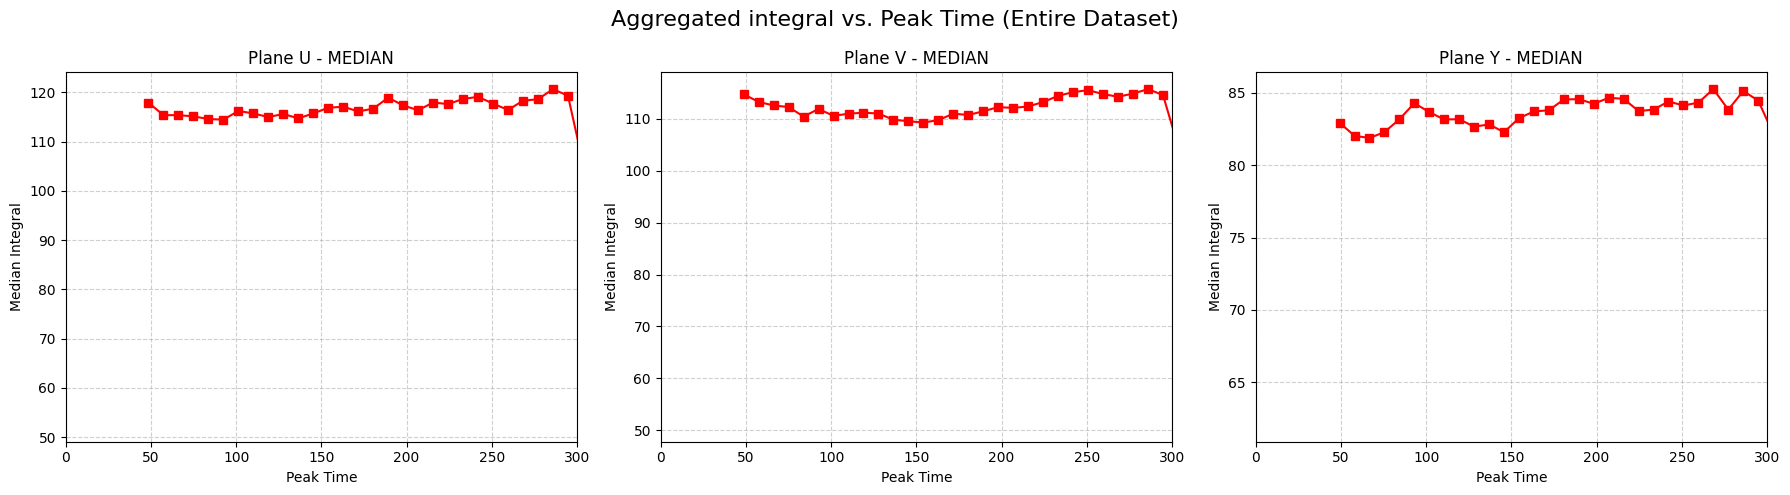

In [25]:
plot_integral_per_plane(c_time,c_int)

# Plotting the Input Features

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
planes = ['u', 'v', 'y']
# ==========================================
# PLOT 1: Histograms of the Features
# ==========================================
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
fig.suptitle("Feature Distributions (Integral and RMS) per Plane")

for i, plane in enumerate(planes):
    # Extract the features for this plane
    features = data[f'{plane}/x']
    
    integral = features[:, 0]
    rms = features[:, 1]
    
    # Calculate standard deviations
    std_integral = np.std(integral)
    std_rms = np.std(rms)

    # Calculate 68% quantiles (0.68)
    spread68_integral = (np.quantile(integral, 0.84) - np.quantile(integral, 0.16))/2
    spread68_rms = (np.quantile(rms, 0.84) - np.quantile(rms, 0.16))/2
    
    # Plot Integral (Column 0)
    axes[i, 0].hist(integral, bins=50, color='blue', alpha=0.7)
    axes[i, 0].set_title(f'Plane {plane.upper()} Integral\n(Std: {std_integral:.2f} | 68% Spread: {spread68_integral:.2f})')
    axes[i, 0].set_ylabel('Count')
    
    # Plot RMS (Column 1)
    axes[i, 1].hist(rms, bins=50, color='red', alpha=0.7)
    axes[i, 1].set_title(f'Plane {plane.upper()} RMS\n(Std: {std_rms:.2f} | 68% Spread: {spread68_rms:.2f})')

plt.tight_layout()
plt.savefig("feature_distributions.pdf", format='pdf', bbox_inches='tight')
plt.show()



In [14]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

# 1. Load the data
file_path = "/scratch/7DayLifetime/cerati/concat-final-makeup.tiny.gnn.h5" # no noise
file_path1 = "/scratch/7DayLifetime/cerati/concat-final-makeup.tiny.gnn.var.h5"   # fixed noise
file_path2 = "/home/hnayak/nugraph_project/noisy_data/ten_percent_noise/concat-final-makeup.tiny.gnn.noisy_gaussian.h5"   # 10% noise
file_path3 = "/home/hnayak/nugraph_project/noisy_data/20_percent_noise/concat-final-makeup.tiny.gnn.noisy_gaussian.h5"   # 20% noise
file_path4 = "/home/hnayak/nugraph_project/noisy_data/40_percent_noise/concat-final-makeup.tiny.gnn.noisy_gaussian.h5"   # 40% noise

file = h5py.File(file_path4, 'r')
dataset_group = file['dataset']

# 2. Grab the first 100 event keys (or all of them if there are fewer than 100)
event_keys = list(dataset_group.keys())##[:100]
print(f"Combining data from {len(event_keys)} events...")

planes = ['u', 'v', 'y']

# Set up dictionaries to hold lists of arrays before we combine them
combined_data = {plane: {'integral': [], 'rms': []} for plane in planes}

# 3. Loop through the events and collect the data
for key in event_keys:
    event_data = dataset_group[key][()]
    for plane in planes:
        features = event_data[f'{plane}/x']
        combined_data[plane]['integral'].append(features[:, 0])
        combined_data[plane]['rms'].append(features[:, 1])

# 4. Concatenate the lists into single, massive numpy arrays per plane
for plane in planes:
    combined_data[plane]['integral'] = np.concatenate(combined_data[plane]['integral'])
    combined_data[plane]['rms'] = np.concatenate(combined_data[plane]['rms'])

Combining data from 22074 events...


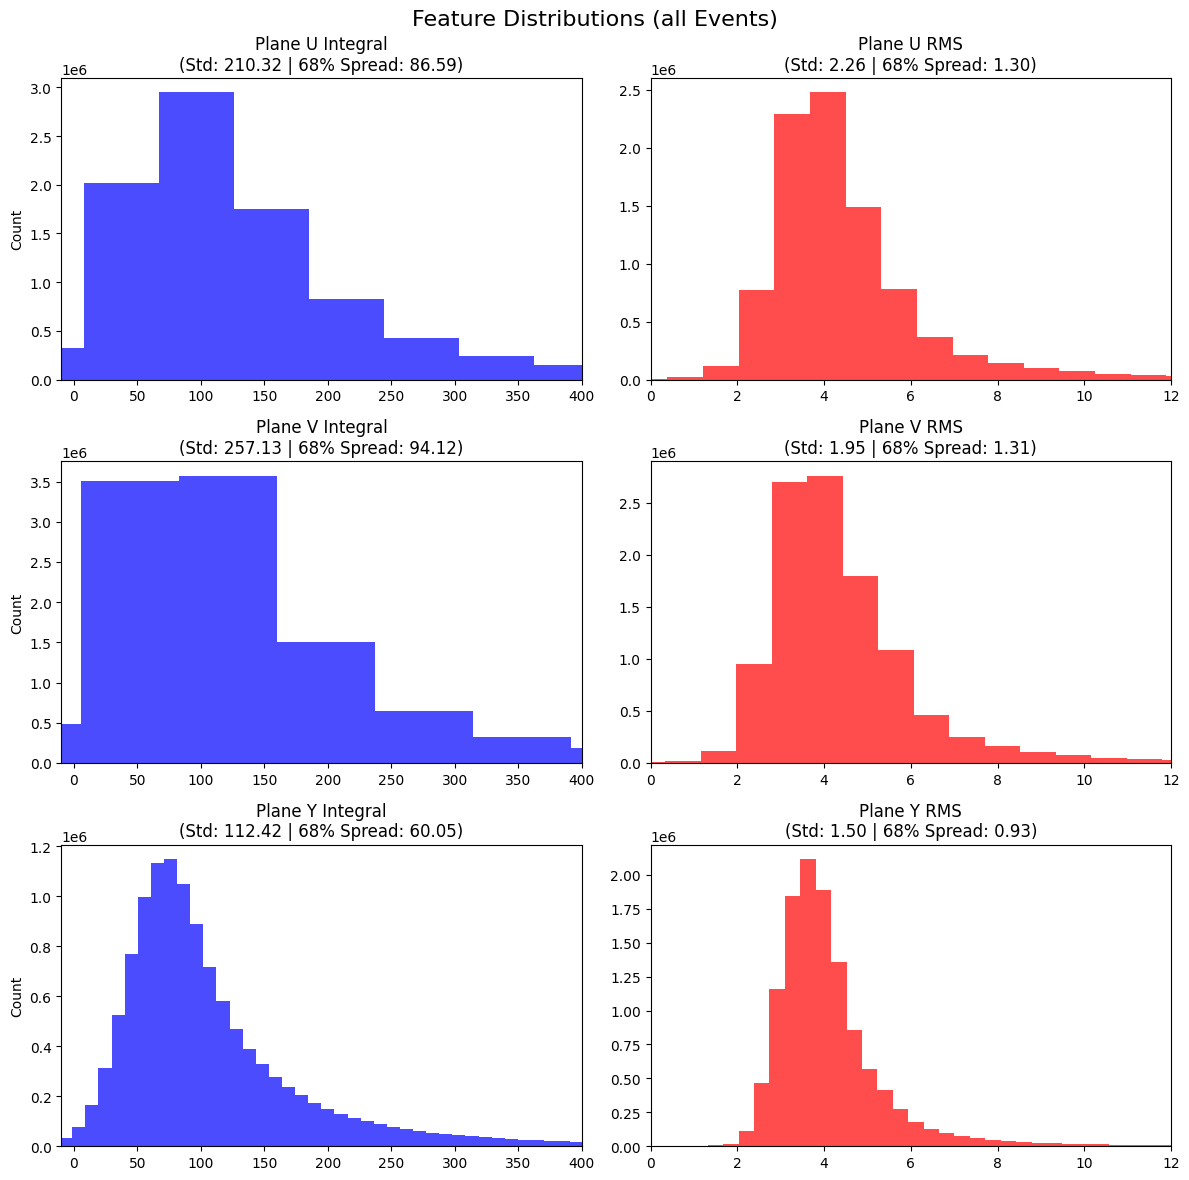

In [15]:
# 5. Set up the figure for Histograms
fig, axes = plt.subplots(3, 2, figsize=(12, 12))
fig.suptitle("Feature Distributions (all Events)", fontsize=16)

# 6. Calculate metrics and plot
for i, plane in enumerate(planes):
    integral = combined_data[plane]['integral']
    rms = combined_data[plane]['rms']
    
    # Calculate standard deviations (sensitive to outliers)
    std_integral = np.std(integral)
    std_rms = np.std(rms)
    
    # Calculate Robust Sigma: (Q84 - Q16) / 2 (robust to outliers)
    robust_std_integral = (np.quantile(integral, 0.84) - np.quantile(integral, 0.16)) / 2.0
    robust_std_rms = (np.quantile(rms, 0.84) - np.quantile(rms, 0.16)) / 2.0
    
    # Plot Integral (Column 0)
    # Increased bins to 100 to handle the larger volume of data
    axes[i, 0].hist(integral, bins=1000, color='blue', alpha=0.7)
    axes[i, 0].set_title(f'Plane {plane.upper()} Integral\n(Std: {std_integral:.2f} | 68% Spread: {robust_std_integral:.2f})')
    axes[i, 0].set_ylabel('Count')
    axes[i, 0].set_xlim(-10, 400)
    
    # Plot RMS (Column 1)
    axes[i, 1].hist(rms, bins=200, color='red', alpha=0.7)
    axes[i, 1].set_title(f'Plane {plane.upper()} RMS\n(Std: {std_rms:.2f} | 68% Spread: {robust_std_rms:.2f})')
    axes[i, 1].set_xlim(0, 12)

plt.tight_layout()

# Save the plot directly to PDF
plt.savefig("plots/feature_distributions_all_events.png", format='png', bbox_inches='tight')

# Display the plot in the notebook
plt.show()

## Tensor dataset

In [3]:
import nugraph as ng
input_files = 2 #1 or 2
data_batch_size = 64

Data  = ng.data.NuGraphDataModule
Model = ng.models.NuGraph3

source_filename="/scratch/7DayLifetime/cerati/concat-final-makeup.tiny.gnn.h5"
# target_filename="/home/hnayak/nugraph_project/noisy_data/ten_percent_noise/concat-final-makeup.tiny.gnn.noisy_gaussian.h5" # 10% noise
target_filename = "/scratch/7DayLifetime/hnayak/nugraph_data/noisy_data/rms_scaled_noise/concat-final-makeup.tiny.gnn.rescaled.h5"

if input_files == 1:
   nudata = Data(model=Model, batch_size=data_batch_size, data_source_path=source_filename)
elif input_files == 2:
   nudata = Data(model=Model, batch_size=data_batch_size, data_source_path=source_filename, data_target_path=target_filename)

nudata.event_classes = ['cc_nue', 'cc_numu', 'cc_nutau', 'nc']
print(nudata)
print(nudata.semantic_classes)
print(nudata.event_classes)

{Train dataloader: size=19868}
{Validation dataloader: size=1103}
{Test dataloader: size=1103}
{Predict dataloader: None}
['MIP', 'HIP', 'shower', 'michel', 'diffuse']
['cc_nue', 'cc_numu', 'cc_nutau', 'nc']


In [3]:
dir(nudata)

['CHECKPOINT_HYPER_PARAMS_KEY',
 'CHECKPOINT_HYPER_PARAMS_NAME',
 'CHECKPOINT_HYPER_PARAMS_TYPE',
 '__annotations__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__jit_unused_properties__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_log_hyperparams',
 '_set_hparams',
 '_to_hparams_dict',
 'add_data_args',
 'allow_zero_length_dataloader_with_multiple_devices',
 'balance_frac',
 'batch_size',
 'collate_func',
 'combined_test',
 'combined_train',
 'combined_val',
 'event_classes',
 'from_datasets',
 'gen',
 'generate_samples',
 'hparams',
 'hparams_initial',
 'load_from_checkpoint',
 'load_state_dict',
 'name',
 'num_workers',
 'on_after_batch_transfer',
 'on_before_batch_transfer',
 'on_exception',
 'plan

In [4]:
print(len(nudata.test_dataset))

1103


In [10]:
print(len(nudata.train_dataloader()))

310


In [15]:
nudata.test_dataset[-100]["hit"]['x']

tensor([[510.6000,  79.6026,  41.0209,   4.2754,   0.0000],
        [510.3000,  79.5983,  72.6345,   3.6978,   0.0000],
        [510.0000,  79.6520,  40.1773,   3.6409,   0.0000],
        ...,
        [143.1000,  70.5809,  69.0865,   3.2247,   2.0000],
        [116.4000,  67.6474,  71.6456,   3.9798,   2.0000],
        [116.1000,  67.8412, 139.8161,   5.2463,   2.0000]])

In [14]:
nudata.test_dataset_target[-100]['hit']['x']

tensor([[510.6000,  79.6026,  41.0209,   4.2510,   0.0000],
        [510.3000,  79.5983,  72.6345,   3.6767,   0.0000],
        [510.0000,  79.6520,  40.1773,   3.6199,   0.0000],
        ...,
        [143.1000,  70.5809,  69.0865,   3.2234,   2.0000],
        [116.4000,  67.6474,  71.6456,   3.9853,   2.0000],
        [116.1000,  67.8412, 139.8161,   5.2529,   2.0000]])